# CS383 — Assignment 2
## EDA and Visualization Report: NYC 311 Resolution Times

*Due: see LMS*

### Scenario
Your local Community Board office has asked you, as a data intern, to look into how long 311
complaints take to get resolved across the city. They need two things from you:

1. The supporting statistical analysis (distribution, outliers, borough comparison, correlation).
2. **One** short, plain-language write-up of a single finding that a board member — someone who has
   never opened a notebook or a spreadsheet — could read in thirty seconds and actually understand.

This is exactly the skill Lecture 5 built toward: doing the technical work, then translating it.

---

### Academic integrity and using AI

This assignment allows AI-assisted coding, the same way Lecture 5's Optional Challenge did — but the line is about *what* AI is allowed to do, not *whether* you can use it at all.

**Allowed** — using an AI tool (Claude, ChatGPT, GitHub Copilot, etc.) to help write the *mechanical* code in each deliverable's code cell: computing a statistic, building a chart, computing a correlation. You decide what needs to be computed; AI can help with how.

**Not allowed** — having AI write your reasoning, interpretation, or written answers. The outlier-cause reasoning (Deliverable 2), the borough comparison interpretation (Deliverable 3), the confounder you name (Deliverable 4), and the plain-language report (Deliverable 5) are the actual statistical judgment this assignment is testing. That judgment has to be yours.

**If you use AI for a code cell, add a one-line comment directly above it naming the prompt**, for example:

```python
# AI prompt: "write code to compute the IQR bounds for resolution_time_hours"
q1, q3 = ...
```

Only comment the lines that were actually AI-assisted — don't add it to code you wrote yourself.

A good test either way: if you can't explain — out loud, without looking anything up — exactly what every line of your submitted notebook does and *why it's the right computation for this question*, that's a sign you leaned on AI too much, whether or not you commented it.

---

### Getting started

Run the cell below once. It loads the same NYC 311 snapshot used in Lecture 5 (or realistic sample
data if the shared file isn't available). **Do not skip or modify this cell** — every deliverable
below assumes `complaints_df` exists with these columns.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

try:
    raw_path = os.path.expanduser("~/shared/nyc311_snapshot.csv")
    complaints_df = pd.read_csv(raw_path).head(10000)
    complaints_df["created_date"] = pd.to_datetime(complaints_df["created_date"])
    complaints_df["closed_date"] = pd.to_datetime(complaints_df["closed_date"])
    live = True

except Exception:
    # Offline fallback, in case there is no internet connection in the room.
    rng = np.random.default_rng(383)
    n = 10000
    complaint_types = ["Noise - Residential", "Illegal Parking", "HEAT/HOT WATER",
                        "Blocked Driveway", "Street Condition", "Water System",
                        "PAINT/PLASTER", "Damaged Tree", "Sewer", "Rodent"]
    boroughs_list = ["MANHATTAN", "BROOKLYN", "QUEENS", "BRONX", "STATEN ISLAND"]
    agency_list = ["NYPD", "HPD", "DOB", "DSNY", "DOT", "DOHMH"]
    agency_p = [0.65, 0.15, 0.05, 0.05, 0.05, 0.05]

    n_days = 90
    days = pd.date_range("2026-01-01", periods=n_days, freq="D")
    day_weight = np.where(days.dayofweek >= 5, 0.6, 1.0)
    day_weight = day_weight / day_weight.sum()

    day_idx = rng.choice(n_days, size=n, p=day_weight)
    created = days[day_idx] + pd.to_timedelta(rng.integers(0, 24 * 60, size=n), unit="m")

    agency = rng.choice(agency_list, size=n, p=agency_p)
    is_nypd_fallback = agency == "NYPD"

    still_open = rng.random(n) < 0.15
    # NYPD dispatches and closes tickets same-day; other agencies (inspections,
    # scheduled follow-up) take much longer -- mirrors the real signal in the
    # live snapshot, so Deliverable 4 has something real to find offline too.
    resolution_hours = np.where(
        is_nypd_fallback,
        rng.gamma(shape=1.5, scale=0.8, size=n),
        rng.gamma(shape=2.0, scale=60.0, size=n),
    )
    closed = created + pd.to_timedelta(resolution_hours, unit="h")

    complaints_df = pd.DataFrame({
        "complaint_type": rng.choice(
            complaint_types, size=n,
            p=[0.18, 0.15, 0.14, 0.10, 0.10, 0.09, 0.08, 0.06, 0.05, 0.05],
        ),
        "borough": rng.choice(boroughs_list, size=n, p=[0.22, 0.32, 0.26, 0.16, 0.04]),
        "agency": agency,
        "created_date": created,
        "closed_date": np.where(still_open, pd.NaT, closed),
    })
    complaints_df["closed_date"] = pd.to_datetime(complaints_df["closed_date"])
    live = False

complaints_df["resolution_time_hours"] = (
    complaints_df["closed_date"] - complaints_df["created_date"]
).dt.total_seconds() / 3600
complaints_df["hour_filed"] = complaints_df["created_date"].dt.hour

print(f"{'Shared snapshot' if live else 'Offline fallback'} data: {len(complaints_df):,} 311 records")
complaints_df.head()

Shared snapshot data: 10,000 311 records


,unique_key,created_date,closed_date,agency,complaint_type,descriptor,location_type,incident_zip,incident_address,street_name,...,borough,status,resolution_description,community_board,open_data_channel_type,latitude,longitude,due_date,resolution_time_hours,hour_filed
0,68843617,2026-04-30 20:10:36,2026-05-06 23:04:54,HPD,DOOR/WINDOW,WINDOW FRAME,RESIDENTIAL BUILDING,10452.0,95 WEST 162 STREET,WEST 162 STREET,...,BRONX,Closed,HPD attempted to conduct an inspection in resp...,04 BRONX,PHONE,40.831393,-73.929322,NaN,146.905000,20
1,69542860,2026-06-30 22:01:12,2026-06-30 23:48:04,NYPD,Abandoned Vehicle,With License Plate,Street/Sidewalk,10001.0,7 AVENUE,7 AVENUE,...,MANHATTAN,Closed,The New York City Police Department responded ...,04 MANHATTAN,PHONE,40.744761,-73.995153,NaN,1.781111,22
2,67349425,2025-12-31 22:54:54,2025-12-31 23:37:37,NYPD,Noise - Residential,Loud Music/Party,Residential Building/House,11230.0,1571 EAST 3 STREET,EAST 3 STREET,...,BROOKLYN,Closed,The New York City Police Department responded ...,12 BROOKLYN,ONLINE,40.612198,-73.971478,NaN,0.711944,22
3,69919607,2026-07-31 23:02:58,2026-08-25 00:00:00,DOB,General Construction/Plumbing,Curb Cut/Driveway/Carport - Illegal,NaN,11219.0,1222 45 STREET,45 STREET,...,BROOKLYN,Closed,The Department of Buildings reviewed this comp...,12 BROOKLYN,UNKNOWN,40.638181,-73.991320,NaN,576.950556,23
4,69188560,2026-05-31 22:40:18,2026-06-01 04:06:53,NYPD,Illegal Parking,Posted Parking Sign Violation,Street/Sidewalk,10463.0,2655 NETHERLAND AVENUE,NETHERLAND AVENUE,...,BRONX,Closed,The New York City Police Department responded ...,08 BRONX,ONLINE,40.879042,-73.915291,NaN,5.443056,22


---

### Explore before you answer

Before jumping into the required questions, take a few minutes to look around:

- What does `complaints_df.describe()` show you about `resolution_time_hours`?
- How many complaints are still open (no `closed_date`) and therefore have no resolution time?
- Which boroughs and complaint types show up most often?

Use the scratch cell below (and add more cells if you want) to explore. This part isn't graded
directly, but it'll make the required questions much easier.

In [2]:
# Scratch space -- explore complaints_df here.
print(complaints_df["resolution_time_hours"].describe())

print("Still open:", complaints_df["closed_date"].isna().sum())

print("Negative times:", (complaints_df["resolution_time_hours"] < 0).sum())

print(complaints_df["borough"].value_counts())
print(complaints_df["complaint_type"].value_counts().head(10))

print("\n", complaints_df["agency"].value_counts())





count    9228.000000
mean       73.925779
std       316.816136
min         0.000000
25%         0.716111
50%         2.237778
75%        17.124444
max      5306.219444
Name: resolution_time_hours, dtype: float64
Still open: 772
Negative times: 0
borough
BROOKLYN         2909
QUEENS           2406
BRONX            2335
MANHATTAN        2008
STATEN ISLAND     333
Unspecified         9
Name: count, dtype: int64
complaint_type
Noise - Residential        2109
Illegal Parking            1630
Noise - Street/Sidewalk    1179
HEAT/HOT WATER              811
Blocked Driveway            606
Noise - Commercial          423
Noise - Vehicle             229
UNSANITARY CONDITION        201
Noise                       179
Street Condition            160
Name: count, dtype: int64

 agency
NYPD     6623
HPD      1528
DOT       394
DSNY      383
DEP       373
DOB       189
DOHMH     169
DPR       129
TLC        90
DHS        56
DCWP       39
OOS        15
EDC        12
Name: count, dtype: int64


---

## Required Deliverable 1 — Distribution of Resolution Times (15 pts)

Compute the **mean**, **median**, and **standard deviation** of `resolution_time_hours` (drop missing
values first — those are complaints that are still open). Then make one histogram showing the shape of
the distribution.

In 1-2 sentences: is the distribution symmetric or skewed? What does that imply about whether the mean
or the median is the more honest way to describe a "typical" complaint's resolution time?

Mean: 73.92577851827771
Median: 2.2377777777777776
Std: 316.81613614430967


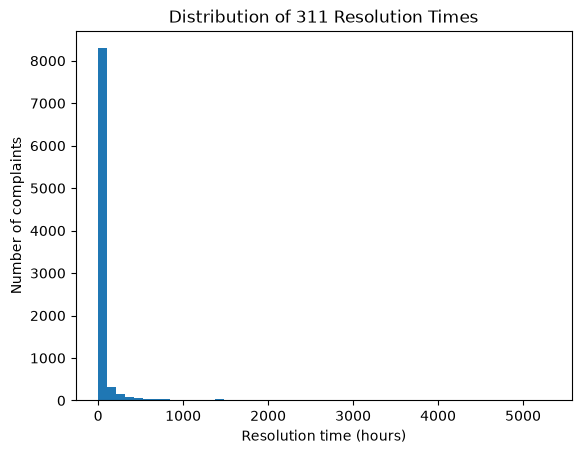

In [3]:
# Your code here.
# Drop still-open complaints
resolved = complaints_df.dropna(subset=["resolution_time_hours"])

print("Mean:", resolved["resolution_time_hours"].mean())
print("Median:", resolved["resolution_time_hours"].median())
print("Std:", resolved["resolution_time_hours"].std())

plt.hist(resolved["resolution_time_hours"], bins=50)
plt.xlabel("Resolution time (hours)")
plt.ylabel("Number of complaints")
plt.title("Distribution of 311 Resolution Times")
plt.show()


**Your answer (symmetric or skewed, mean vs. median): The distribution is more skewed because most complaints close in 2 hours which is the median but there are a few that take months and drag the average up to 73 hours. This implies that the median is the more honest way to describe a typical complaint because the average rises because of the rare cases that take longer. **



---

## Required Deliverable 2 — Flagging Outliers with the IQR Rule (15 pts)

Using the same 1.5×IQR rule from lecture, flag which resolution times count as outliers. Report the
IQR bounds and how many complaints get flagged.

**Before you write the code**, answer: do you think these flagged cases are more likely data-entry
errors, or real complaints that genuinely took an unusually long time? Justify your answer in 1-2
sentences.

**Your reasoning (before you code): I think these flagged cases are more likely real complaints because there wasn't any misleading times. **



In [4]:
# Your code here.
Q1 = resolved["resolution_time_hours"].quantile(0.25)
Q3 = resolved["resolution_time_hours"].quantile(0.75)
IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR
print("Lower bound:", lower)
print("Upper bound:", upper)


outliers = resolved[resolved["resolution_time_hours"] > upper]
print("Number of outliers:", len(outliers))


Lower bound: -23.896388888888886
Upper bound: 41.73694444444444
Number of outliers: 1696


---

## Required Deliverable 3 — Comparing Boroughs (15 pts)

Using a box plot, compare `resolution_time_hours` across the five boroughs. Which borough has the
**highest** median resolution time, and which has the **lowest**? Report the median for each, and
state the size of the gap between them in hours.

Note: a handful of rows have `borough` set to `"Unspecified"` rather than a real borough — filter
those out first, the same way you'd drop any row that doesn't answer the question being asked.

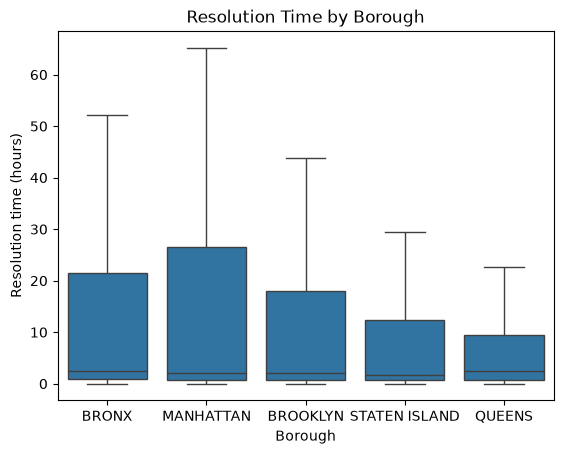

borough
STATEN ISLAND    1.711944
MANHATTAN        2.015000
BROOKLYN         2.064167
BRONX            2.483611
QUEENS           2.520833
Name: resolution_time_hours, dtype: float64
Gap: 0.808888888888889 hours


In [5]:
# Your code here.

boroughs = resolved[resolved["borough"] != "Unspecified"]

sns.boxplot(data=boroughs, x="borough", y="resolution_time_hours", showfliers=False)
plt.xlabel("Borough")
plt.ylabel("Resolution time (hours)")
plt.title("Resolution Time by Borough")
plt.show()

medians = boroughs.groupby("borough")["resolution_time_hours"].median().sort_values()
print(medians)

print("Gap:", medians.max() - medians.min(), "hours")

**Your answer (slowest / fastest borough, size of the gap): Queens is the borough that has the slowest resolution time with a medain of 2.52 hours and Staten Island has the fastest time with 1.71 hours they also have a gap between them about 0.81 hours. **



---

## Required Deliverable 4 — Correlation and a Causation Check (15 pts)

Create a new column `is_nypd` that is `1` when `agency == "NYPD"` and `0` otherwise. Compute the
correlation between `is_nypd` and `resolution_time_hours`.

This one comes out meaningfully different from zero — not just noise. Does that mean NYPD is simply
"better" or "faster" at its job than other agencies? Name **one plausible confounding variable** that
could explain most of this relationship without NYPD's efficiency directly causing it — the same kind
of check done for boroughs in Lecture 5's ice-cream/drowning example.

Note: some agencies only appear a handful of times in this data. An agency's median resolution time
isn't trustworthy if it's based on only a few complaints — the same problem as the `"Unspecified"`
borough in Deliverable 3. When you rank agencies, keep only agencies with at least 30 resolved
complaints.

In [6]:
# Your code here. 
complaints_df["is_nypd"] = np.where(complaints_df["agency"] == "NYPD", 1, 0)

corr = complaints_df["is_nypd"].corr(complaints_df["resolution_time_hours"])
print("Correlation:", corr)

counts = resolved["agency"].value_counts()
big_agencies = counts[counts >= 30].index
agency_medians = resolved[resolved["agency"].isin(big_agencies)].groupby("agency")["resolution_time_hours"].median().sort_values()
print(agency_medians)


Correlation: -0.3476126306713872
agency
NYPD       1.255833
DHS        6.455694
DEP       32.533333
DSNY      34.554167
TLC       50.766389
DOT       60.497639
DPR       62.789722
HPD       67.100833
DOHMH    172.929306
DOB      337.557778
Name: resolution_time_hours, dtype: float64


**Your answer (correlation strength + one plausible confounder): The correaltion between is_nypd and resolution time is about −0.34. This means that NYPD complaints usually get closed faster than other agencies. This doesn't mean that NYPD is better at its job since the other agencies could be dealing with complaints that take days to fix while NYPD deals with complaints that can be solved faster such as a noise complaints



---

## Required Deliverable 5 — The Non-Technical Report (30 pts)

Pick **one** finding from Deliverables 1-4 (or something else you noticed while exploring) that an
actual Community Board member — not a data scientist — would care about.

Using the four-part framework from lecture, write it up:

1. **Lead with the finding** — the one sentence a busy reader would actually remember.
2. **One supporting chart** — the smallest chart that proves the finding, not every chart you made.
3. **No jargon** — "IQR," "correlation," "standard deviation," and "outlier" mean nothing to this
   reader. Say what you found in plain language instead.
4. **State the "so what"** — why should this reader care? What would they do differently knowing this?

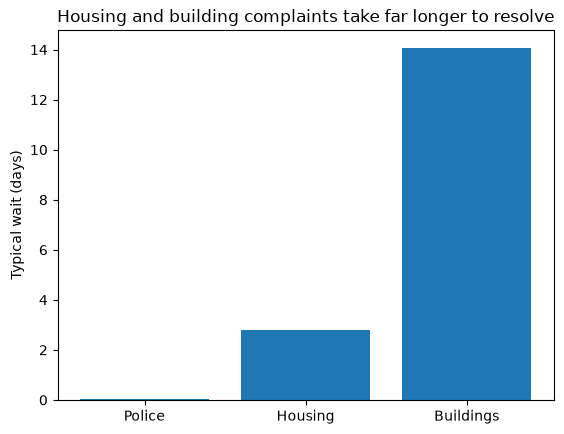

In [7]:
plt.bar(["Police", "Housing", "Buildings"],
        [agency_medians["NYPD"] / 24, agency_medians["HPD"] / 24, agency_medians["DOB"] / 24])
plt.ylabel("Typical wait (days)")
plt.title("Housing and building complaints take far longer to resolve")
plt.show()

**Your report (plain language): Most police complaints such as noise or illegal parking get solved in about an hour. But housing complaints such as no heat or repairs usually take about 3 days and Building complaints usually take about 2 weeks. This doesn’t mean some departments are better than another. But fixing a building or a heating problem just takes longer than checking on a noise complaint. This matters because people with housing and building problems wait the longest and these are more serious problems like having no heat in winter.**



---

### AI Check

In 1-2 sentences: identify one line of AI-generated code you used in this assignment and how you verified it was correct **for this specific dataset** (remember, the data might come from the live snapshot or the offline fallback, and columns like `agency` are unevenly represented). If you didn't use AI this time, just note that.

**Your answer: I used AI to write resolved = complaints_df.dropna(subset=["resolution_time_hours"]). I checked it by making sure the number of rows left and the complaints that were open still added up to 10,000 and that the mean, median, and standard deviation matched what describe() showed.**



---

## Grading Rubric

| Criterion | Points |
|---|---|
| Deliverable 1 — stats computed correctly; histogram shown; skew/mean-vs-median answer is correct | 15 |
| Deliverable 2 — IQR bounds and outlier count correct; reasoning is stated and defensible | 15 |
| Deliverable 3 — box plot correct; slowest/fastest borough and gap correctly identified | 15 |
| Deliverable 4 — correlation computed correctly; confounder is plausible and genuinely independent | 15 |
| Deliverable 5 — finding is genuinely non-technical, chart is the *right* one, "so what" is present | 30 |
| Notebook runs top to bottom without errors | 10 |
| **Total** | **100** |

---

## Submission

### GitHub (same repo as Assignment 1)

1. Use the same `cs383-assignments` repo you created for Assignment 1. Inside it, create a new folder:
   `assignment2/`.
2. Put your completed notebook in that folder, keeping its original filename:
   `assignment2_311_eda_report.ipynb`.

```bash
git add -A
git commit -m "Assignment 2: 311 EDA report"
git push
```

Submit the **direct link to your notebook file on GitHub** (the URL should end in
`assignment2/assignment2_311_eda_report.ipynb`) on BrightSpace under **Assignment 2**.

Make sure your notebook runs top to bottom without errors before you submit — a notebook that only
works because cells were run out of order will not be graded as passing.